In [1]:
import warnings
import numpy as np
import pandas as pd
import holidays
import matplotlib.pyplot as plt
import statsmodels.api as sm
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.stats.diagnostic import acorr_ljungbox
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit

warnings.filterwarnings("ignore")


1. BACA DATA
              jk
tanggal         
2023-01-01   149
2023-01-02  1015
2023-01-03  1685
2023-01-04   770
2023-01-05   811
jumlah baris : 1382
rentang      : 2023-01-01 sampai 2026-10-13
data kosong  : 0
tanggal bolong: 0
count    1382.00
mean      808.01
std       377.94
min       113.00
25%       570.50
50%       928.50
75%      1071.75
max      1760.00
Name: jk, dtype: float64
              jk
tanggal         
2026-10-11   189
2026-10-12  1435
2026-10-13   426
baris terakhir dibuang karena data hari itu belum lengkap


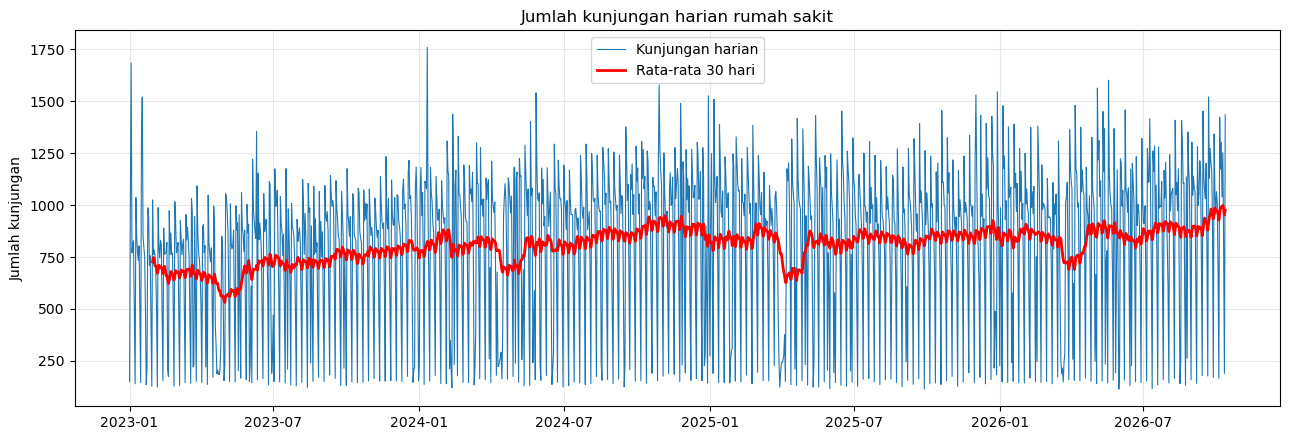

Senin     1137.0
Selasa    1006.0
Rabu       969.0
Kamis      893.0
Jumat      898.0
Sabtu      606.0
Minggu     151.0
Name: jk, dtype: float64


In [2]:
print("=" * 60)
print("1. BACA DATA")
print("=" * 60)
df = pd.read_excel("Harian Total 2023 sd 2026.xlsx")
df["tanggal"] = pd.to_datetime(df["tanggal"])
df = df[["tanggal", "jk"]].set_index("tanggal")
print(df.head())
print("jumlah baris :", len(df))
print("rentang      :", df.index.min().date(), "sampai", df.index.max().date())
print("data kosong  :", df["jk"].isna().sum())
print("tanggal bolong:", len(pd.date_range(df.index.min(), df.index.max())) - len(df))
print(df["jk"].describe().round(2))

print(df.tail(3))
df = df.iloc[:-1]
df.index.freq = "D"
print("baris terakhir dibuang karena data hari itu belum lengkap")

plt.figure(figsize=(13, 4.5))
plt.plot(df.index, df["jk"], lw=0.8, label="Kunjungan harian")
plt.plot(df.index, df["jk"].rolling(30).mean(), color="red", lw=2, label="Rata-rata 30 hari")
plt.title("Jumlah kunjungan harian rumah sakit")
plt.ylabel("Jumlah kunjungan")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

hari = ["Senin", "Selasa", "Rabu", "Kamis", "Jumat", "Sabtu", "Minggu"]
rata_hari = df.groupby(df.index.dayofweek)["jk"].mean().round(0)
rata_hari.index = hari
print(rata_hari)

2. UJI STASIONERITAS DATA ASLI

Data asli
  ADF  : statistik = -4.9501, p-value = 0.0000 -> stasioner
  KPSS : statistik = 1.9376, p-value = 0.0100 -> tidak stasioner
  Simpulan: BELUM STASIONER (hasil kedua uji berbeda)


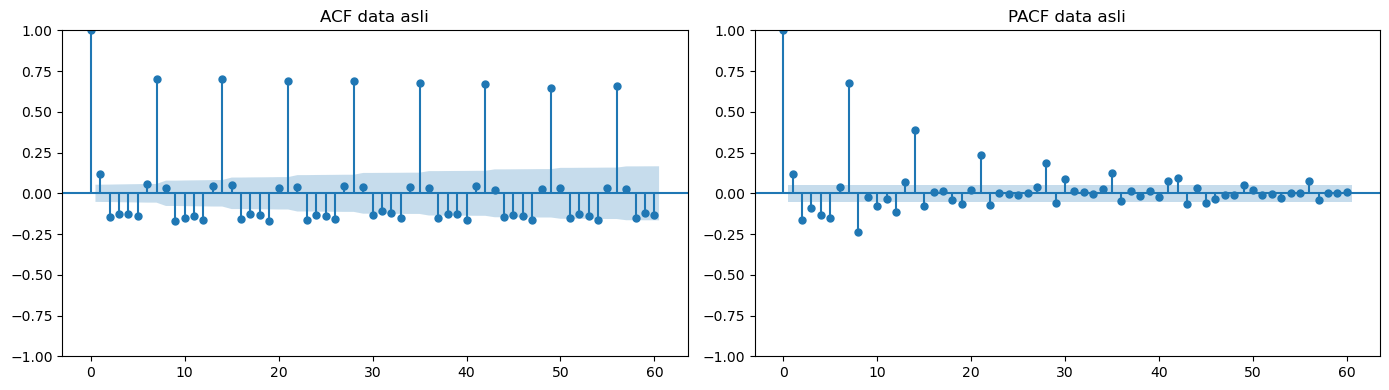

In [3]:
print("=" * 60)
print("2. UJI STASIONERITAS DATA ASLI")
print("=" * 60)


def uji_stasioner(seri, nama):
    seri = pd.Series(seri).dropna().astype(float)
    adf = adfuller(seri, autolag="AIC")
    kp = kpss(seri, regression="c", nlags="auto")
    ket_adf = "stasioner" if adf[1] < 0.05 else "tidak stasioner"
    ket_kpss = "stasioner" if kp[1] > 0.05 else "tidak stasioner"
    if ket_adf == "stasioner" and ket_kpss == "stasioner":
        simpulan = "STASIONER"
    elif ket_adf == "tidak stasioner" and ket_kpss == "tidak stasioner":
        simpulan = "TIDAK STASIONER"
    else:
        simpulan = "BELUM STASIONER (hasil kedua uji berbeda)"
    print(f"\n{nama}")
    print(f"  ADF  : statistik = {adf[0]:.4f}, p-value = {adf[1]:.4f} -> {ket_adf}")
    print(f"  KPSS : statistik = {kp[0]:.4f}, p-value = {kp[1]:.4f} -> {ket_kpss}")
    print(f"  Simpulan: {simpulan}")
    return simpulan


uji_stasioner(df["jk"], "Data asli")

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
plot_acf(df["jk"], lags=60, ax=ax[0])
plot_pacf(df["jk"], lags=60, ax=ax[1], method="ywm")
ax[0].set_title("ACF data asli")
ax[1].set_title("PACF data asli")
plt.tight_layout()
plt.show()

3. DIFFERENCING

Differencing 1 (d = 1)
  ADF  : statistik = -13.8555, p-value = 0.0000 -> stasioner
  KPSS : statistik = 0.1384, p-value = 0.1000 -> stasioner
  Simpulan: STASIONER

Differencing musiman 7 hari (D = 1, s = 7)
  ADF  : statistik = -12.9954, p-value = 0.0000 -> stasioner
  KPSS : statistik = 0.0085, p-value = 0.1000 -> stasioner
  Simpulan: STASIONER


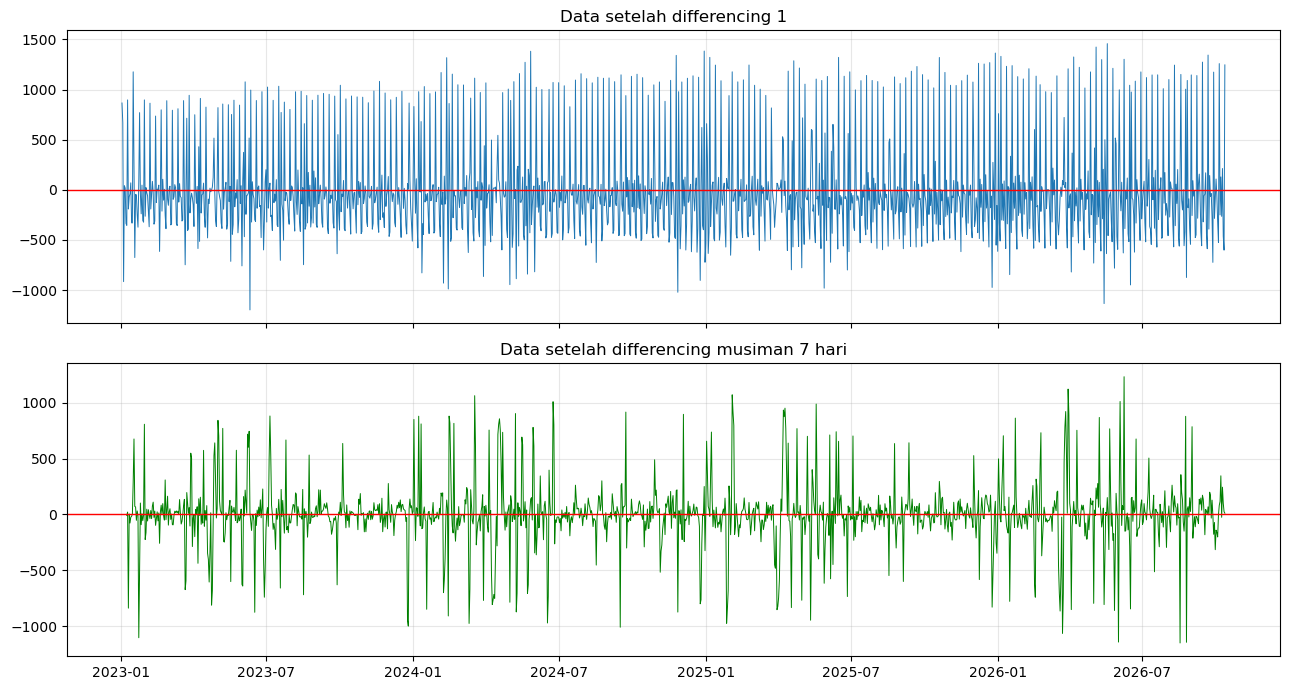

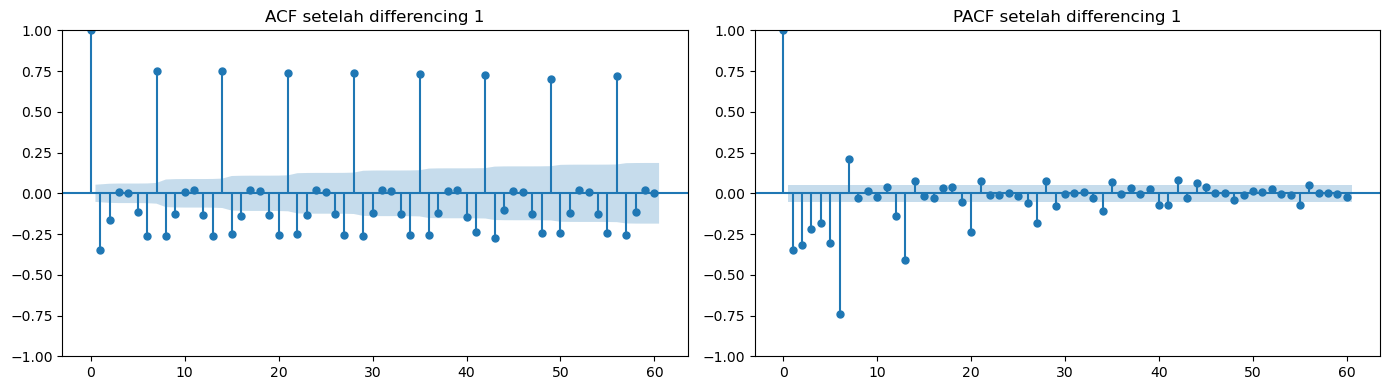

In [4]:
print("=" * 60)
print("3. DIFFERENCING")
print("=" * 60)
diff1 = df["jk"].diff().dropna()
diff7 = df["jk"].diff(7).dropna()
uji_stasioner(diff1, "Differencing 1 (d = 1)")
uji_stasioner(diff7, "Differencing musiman 7 hari (D = 1, s = 7)")

fig, ax = plt.subplots(2, 1, figsize=(13, 7), sharex=True)
ax[0].plot(diff1.index, diff1, lw=0.7)
ax[0].axhline(0, color="red", lw=1)
ax[0].set_title("Data setelah differencing 1")
ax[1].plot(diff7.index, diff7, lw=0.7, color="green")
ax[1].axhline(0, color="red", lw=1)
ax[1].set_title("Data setelah differencing musiman 7 hari")
for a in ax:
    a.grid(alpha=0.3)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
plot_acf(diff1, lags=60, ax=ax[0])
plot_pacf(diff1, lags=60, ax=ax[1], method="ywm")
ax[0].set_title("ACF setelah differencing 1")
ax[1].set_title("PACF setelah differencing 1")
plt.tight_layout()
plt.show()
